# Debiasing importance rankings through orthogonalization

Standardization removes level and scale, and an eigenvector rotation turns correlated features into orthogonal component scores:

$$
Z_{tj}=\frac{X_{tj}-\mu_j}{\sigma_j},
\qquad
Z^{\mathsf T}ZW=W\Lambda,
\qquad
P=ZW,
\qquad
P^{\mathsf T}P=\Lambda.
$$

Here, $X_{tj}$ is feature $j$ at observation $t$; $\mu_j,\sigma_j$ are its sample mean and standard deviation; $Z$ is the standardized matrix. $W$ contains orthonormal eigenvectors; $\Lambda$ is diagonal with descending eigenvalues; $P$ contains the component scores; $\mathsf T$ denotes transpose.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.ensemble import RandomForestClassifier
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.features.feature_importance import ClusteredFeatureImportanceMDA, ClusteredFeatureImportanceMDI, FeatureImportanceMDA, FeatureImportanceMDI, FeatureImportanceSFI, calculate_weighted_tau, conditional_predictive_impact, mdi_plus_importance, orthogonal_features
FIGURES = ROOT / 'outputs' / 'figures' / '14_feature_importance'
TABLES = ROOT / 'outputs' / 'tables' / '14_feature_importance'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
clusters = {'Consumer': ['Food', 'Beer', 'Hshld'], 'Resources': ['Oil', 'Coal', 'Mines'], 'Technology': ['Hardw', 'Softw', 'Chips'], 'Finance': ['Banks', 'Insur', 'Fin']}
selected_features = [feature for values in clusters.values() for feature in values]
trailing_returns = industry_returns[selected_features].rolling(5).sum().shift(1)
market_direction = (industry_returns.mean(axis=1) > 0).astype(int).rename('Market direction')
public_frame = pd.concat([trailing_returns, market_direction], axis=1).dropna()
public_x = public_frame[selected_features]
public_y = public_frame['Market direction']
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def forest(seed, trees=120, depth=5, leaf=10, features=1):
    return RandomForestClassifier(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf, max_features=features, random_state=seed, n_jobs=1, bootstrap=True)

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Orthogonal Directions

The retained dimension is the smallest number of principal directions that reaches the chosen share of total standardized variation:

$$
m=\min\left\{q:\frac{\sum_{r=1}^{q}\lambda_r}{\sum_{r=1}^{p}\lambda_r}\geq\gamma\right\},
\qquad
\gamma=0.90.
$$

Here, $\lambda_r$ is eigenvalue $r$ in descending order; $p$ is the original number of features; $q$ is a candidate retained count. $m$ is the selected count; $\gamma$ is the cumulative-variation threshold, set here to $0.90.$

,Quantity,Value
0,Observations,1755
1,Original features,12
2,Retained components,7
3,Cumulative variation,9.210123e-01
4,Largest absolute off-diagonal product,1.438849e-12
5,Weighted rank agreement,-1.285583e-01


,Component,Eigenvalue,Variation share,Cumulative variation,MDI,Inverse rank
0,PC_1,11367.145839,0.540058,0.540058,0.144748,1
1,PC_2,2897.993827,0.137685,0.677743,0.140003,0.500000
2,PC_3,2183.428527,0.103736,0.781479,0.142552,0.333333
3,PC_4,1141.193920,0.054219,0.835698,0.152101,0.250000
4,PC_5,677.769646,0.032201,0.867899,0.129453,0.200000
5,PC_6,600.399891,0.028525,0.896424,0.146038,0.166667
6,PC_7,517.535034,0.024588,0.921012,0.145105,0.142857


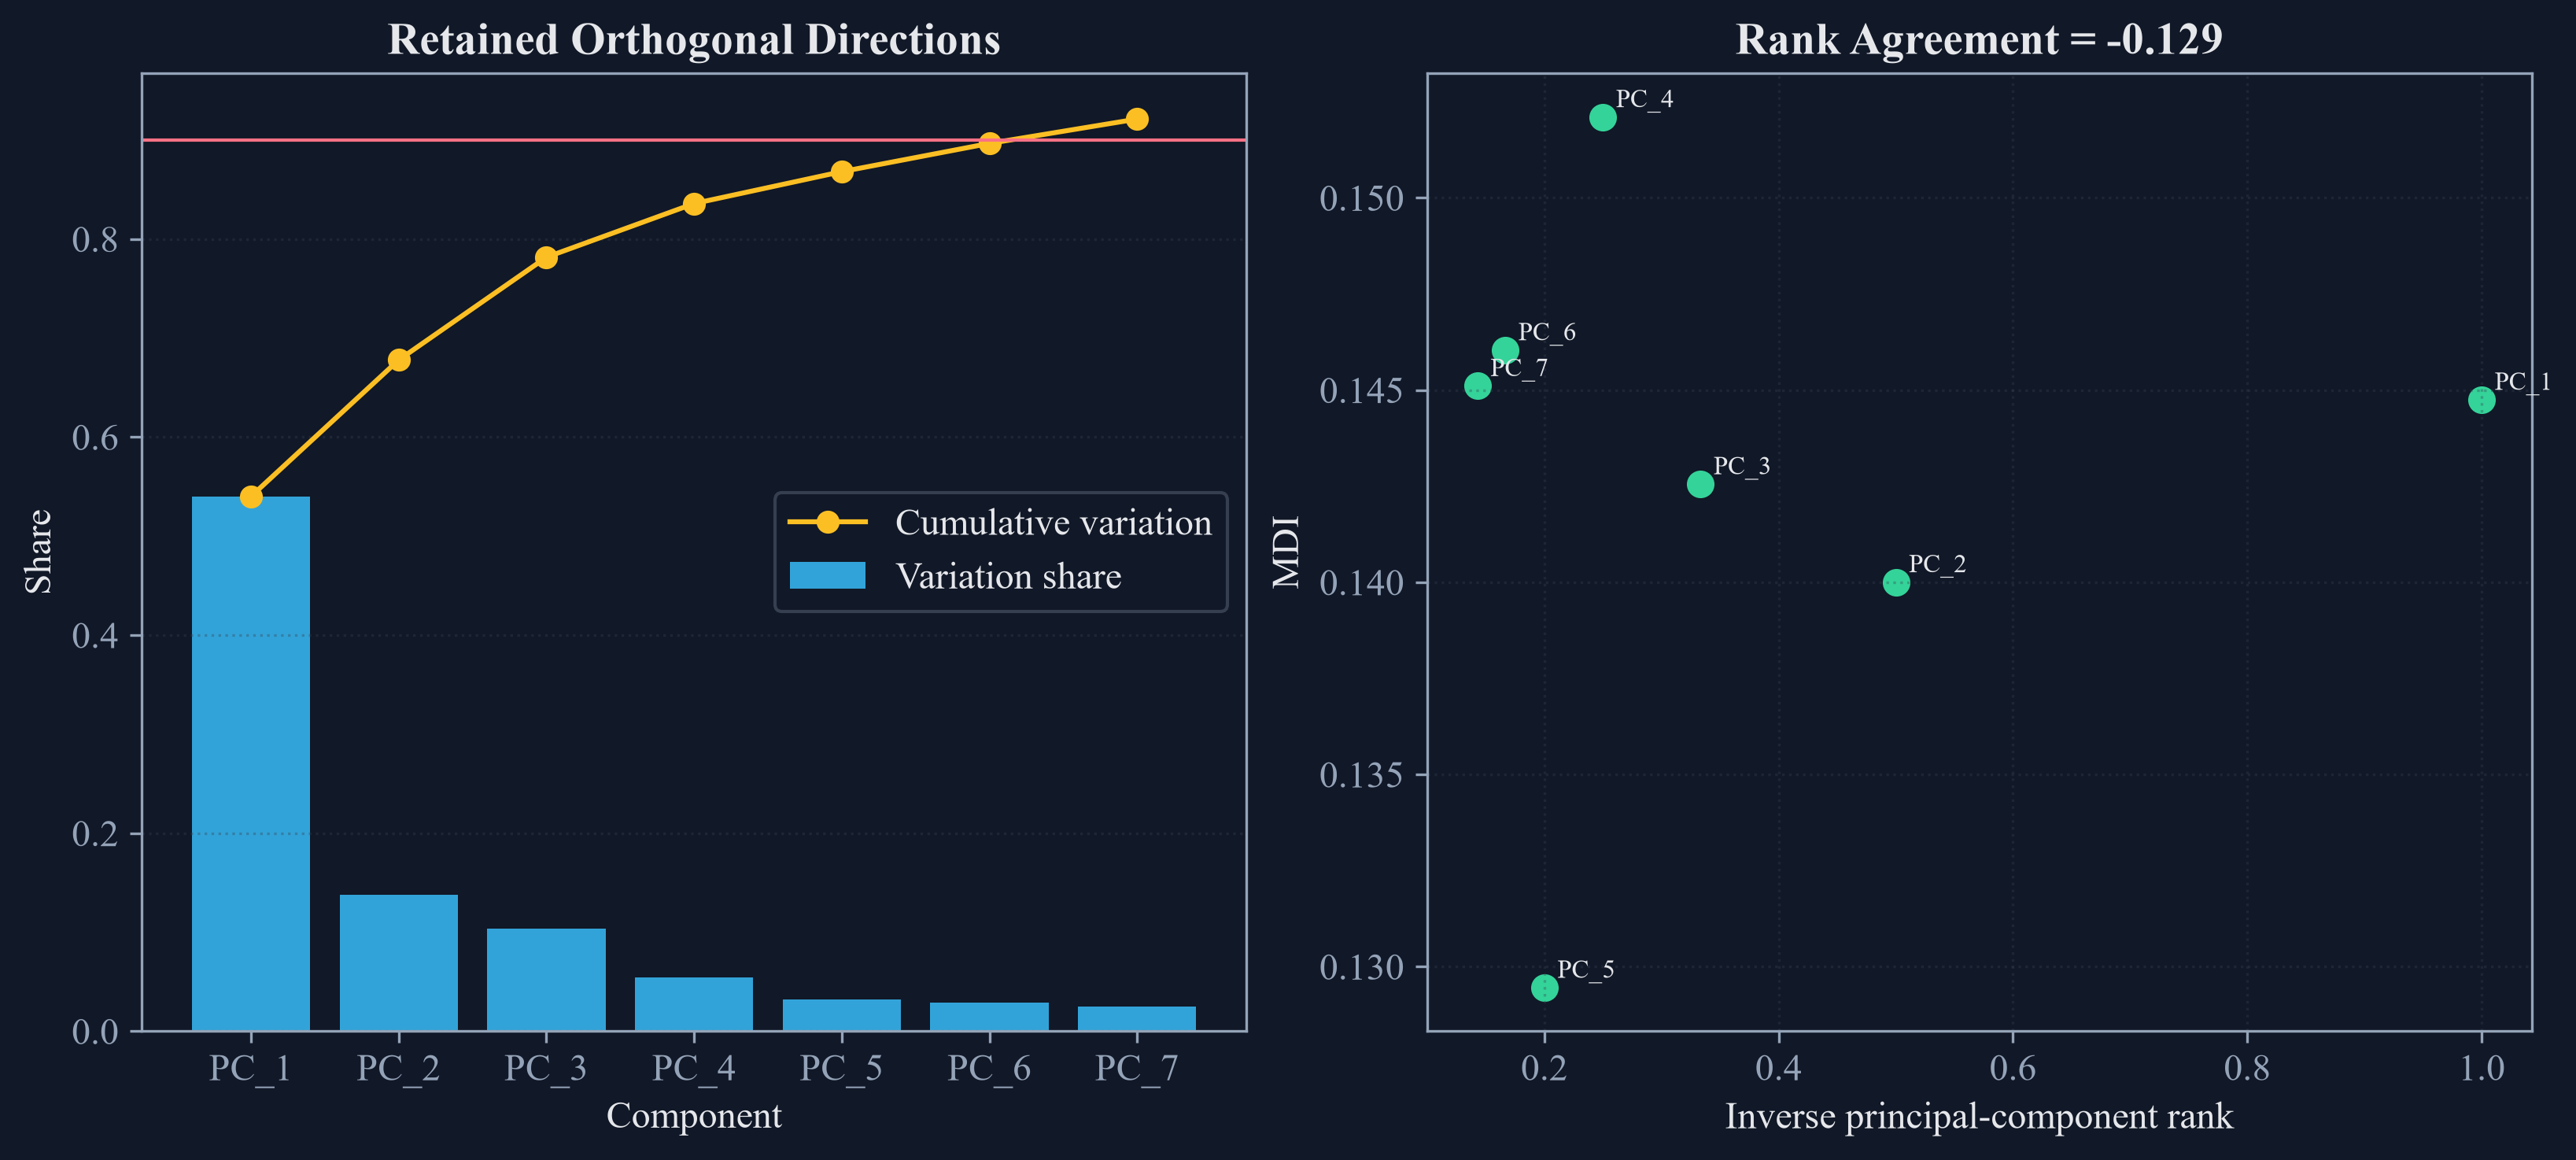

In [2]:
public_components, public_eigen = orthogonal_features(public_x, variance_threshold=0.90)
component_mdi = FeatureImportanceMDI(forest(1241)).compute(public_components, public_y)
component_ranks = np.arange(1, len(public_components.columns) + 1)
weighted_tau = calculate_weighted_tau(component_mdi["Mean"].to_numpy(), component_ranks)
component_gram = public_components.to_numpy().T @ public_components.to_numpy()
off_diagonal = component_gram - np.diag(np.diag(component_gram))
orthogonal_summary = pd.DataFrame({
    "Quantity": ["Observations", "Original features", "Retained components", "Cumulative variation", "Largest absolute off-diagonal product", "Weighted rank agreement"],
    "Value": [len(public_components), public_x.shape[1], public_components.shape[1], public_eigen["CumulativeVariance"].iloc[-1], np.abs(off_diagonal).max(), weighted_tau],
})
save_table(orthogonal_summary, "orthogonal_summary", "Public orthogonalization and rank-agreement summary.", "tab:chapter12-orthogonal-summary", fit=False)
display(orthogonal_summary)

component_importance = pd.DataFrame({
    "Component": public_components.columns,
    "Eigenvalue": public_eigen["EigenValue"].to_numpy(),
    "Variation share": public_eigen["EigenValue"].to_numpy() / (len(public_x) - 1) / public_x.shape[1],
    "Cumulative variation": public_eigen["CumulativeVariance"].to_numpy(),
    "MDI": component_mdi["Mean"].to_numpy(),
    "Inverse rank": 1.0 / component_ranks,
})
save_table(component_importance, "component_importance", "Importance and unsupervised rank of the retained public components.", "tab:chapter12-component-importance", fit=True)
display(component_importance.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.8), constrained_layout=True)
positions = np.arange(1, len(component_importance) + 1)
axes[0].bar(positions, component_importance["Variation share"], color=palette["cyan"], alpha=0.85, label="Variation share")
axes[0].plot(positions, component_importance["Cumulative variation"], color=palette["amber"], marker="o", label="Cumulative variation")
axes[0].axhline(0.90, color=palette["rose"], linewidth=1.0)
axes[0].set_xticks(positions, component_importance["Component"])
axes[0].set_title("Retained Orthogonal Directions")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Share")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.35)
axes[1].scatter(component_importance["Inverse rank"], component_importance["MDI"], color=palette["green"], s=55)
for row in component_importance.itertuples(index=False):
    axes[1].annotate(row.Component, (row._5, row.MDI), xytext=(4, 3), textcoords="offset points", fontsize=8)
axes[1].set_title(f"Rank Agreement = {weighted_tau:.3f}")
axes[1].set_xlabel("Inverse principal-component rank")
axes[1].set_ylabel("MDI")
axes[1].grid(alpha=0.35)
figure.savefig(FIGURES / "public_orthogonal_rank.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_orthogonal_rank.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_orthogonal_rank.png")))
plt.close(figure)

## Weighted Rank Agreement

The released calculation compares component importances with inverse component rank and gives greater influence to agreement near the top:

$$
\tau_h=\operatorname{weightedtau}\!\left(a,r^{-1}\right),
\qquad
a=(a_1,\ldots,a_m),
\qquad
r=(1,\ldots,m).
$$

Here, $a_j$ is the importance of component $j$; $r_j$ is its eigenvalue rank; $r^{-1}$ is the elementwise inverse-rank vector. $m$ is the number of retained components; $\operatorname{weightedtau}$ is SciPy's hyperbolically weighted Kendall comparison; $\tau_h\in[-1,1]$ is its result.

## The Released Simplified Stump-Ridge Score

The released simplified score builds centered split indicators, fits a ridge model on in-bag rows, and measures each feature's partial prediction variance on out-of-bag rows:

$$
\phi_s(x_i)=\mathbf 1\!\left\{x_{i,j(s)}\leq c_s\right\}-\overline\phi_s,
\qquad
\widehat\beta_b=\arg\min_{\beta}\left\{\lVert y_{I_b}-\Phi_{I_b}\beta\rVert_2^2+\lVert\beta\rVert_2^2\right\},
\qquad
\operatorname{RLSI}_j=\frac{1}{B}\sum_{b=1}^{B}\operatorname{Var}_{i\in O_b}\!\left(\sum_{s:j(s)=j}\phi_s(x_i)\widehat\beta_{b,s}\right).
$$

Here, $s$ labels an internal split; $j(s)$ is its feature; $c_s$ is its threshold; $\phi_s$ is the centered split indicator. $\Phi$ collects all indicators; $I_b,O_b$ are the in-bag and out-of-bag rows for tree $b$; $y$ is the binary response; $\widehat\beta_b$ is the ridge coefficient vector. $B$ is the number of used trees; $\operatorname{RLSI}_j$ is the released library's simplified score for feature $j$, not the full MDI+ construction in the paper.

In [3]:
mdi_plus_rows = []
for repetition in range(12):
    current_seed = 12030 + repetition
    current_rng = np.random.default_rng(current_seed)
    current_count = 400
    binary_signal = current_rng.integers(0, 2, current_count)
    current_y = pd.Series(np.logical_xor(binary_signal, current_rng.random(current_count) < 0.30).astype(int))
    current_x = pd.DataFrame({
        "Binary signal": binary_signal,
        "Binary noise": current_rng.integers(0, 2, current_count),
        "Four-level noise": current_rng.integers(0, 4, current_count),
        "Twenty-level noise": current_rng.integers(0, 20, current_count),
        "Continuous noise A": current_rng.normal(size=current_count),
        "Continuous noise B": current_rng.normal(size=current_count),
    })
    bias_forest = RandomForestClassifier(n_estimators=120, max_depth=None, min_samples_leaf=1, max_features=1, random_state=current_seed, n_jobs=1, bootstrap=True)
    current_mdi = FeatureImportanceMDI(bias_forest).compute(current_x, current_y)["Mean"]
    current_plus = mdi_plus_importance(current_x, current_y, random_state=current_seed, n_trees=50, classifier=bias_forest)
    mdi_plus_rows.append({
        "Repetition": repetition + 1,
        "MDI signal": current_mdi["Binary signal"],
        "MDI largest noise": current_mdi.drop("Binary signal").max(),
        "Released simplified score signal": current_plus["Binary signal"],
        "Released simplified score largest noise": current_plus.drop("Binary signal").max(),
        "MDI ranks signal first": current_mdi.idxmax() == "Binary signal",
        "Released simplified score ranks signal first": current_plus.idxmax() == "Binary signal",
    })
mdi_plus_paths = pd.DataFrame(mdi_plus_rows)
mdi_plus_controlled = pd.DataFrame({
    "Method": ["MDI", "Released simplified stump-ridge score"],
    "Signal ranked first, share": [mdi_plus_paths["MDI ranks signal first"].mean(), mdi_plus_paths["Released simplified score ranks signal first"].mean()],
    "Mean signal score": [mdi_plus_paths["MDI signal"].mean(), mdi_plus_paths["Released simplified score signal"].mean()],
    "Mean largest-noise score": [mdi_plus_paths["MDI largest noise"].mean(), mdi_plus_paths["Released simplified score largest noise"].mean()],
})
save_table(mdi_plus_controlled, "mdi_plus_controlled", "Many-value noise comparison over twelve fixed-seed repetitions.", "tab:chapter12-mdi-plus-controlled", fit=True)
display(mdi_plus_controlled.round(6))

,Method,"Signal ranked first, share",Mean signal score,Mean largest-noise score
0,MDI,0,0.146490,0.281231
1,Released simplified stump-ridge score,1,0.039675,0.019256


## Testing conditional predictive impact

The released approximation replaces one feature by a ridge conditional mean plus Gaussian noise and measures the resulting held-out loss increase:

$$
\widetilde X_j=\widehat\mu_j(X_{-j})+\widehat\sigma_j\varepsilon,
\qquad
d_i=L\!\left(\widehat f,\widetilde z_i\right)-L\!\left(\widehat f,z_i\right),
\qquad
\widehat{\operatorname{CPI}}_j=\frac{1}{n}\sum_{i=1}^{n}d_i.
$$

Here, $X_{-j}$ contains all features except $j$; $\widehat\mu_j$ is its ridge prediction of feature $j$; $\widehat\sigma_j$ is residual scale. $\varepsilon$ is a standard-normal draw; $z_i,\widetilde z_i$ are original and replaced observations; $\widehat f$ is fitted without row $i$; $L$ is log loss. $d_i$ is the paired loss difference; $n$ is the number of held-out differences; $\widehat{\operatorname{CPI}}_j$ is their mean.

A one-sided paired t-test asks whether replacing feature $j$ increases expected held-out loss:

$$
t_j=\frac{\overline d_j}{s_{d,j}/\sqrt n},
\qquad
H_{0j}:\mathbb E[d_j]\leq0,
\qquad
H_{1j}:\mathbb E[d_j]>0.
$$

Here, $\overline d_j$ is the mean paired loss difference; $s_{d,j}$ is its sample standard deviation; $n$ is the number of differences. $t_j$ is the test statistic; $H_{0j}$ is the nonpositive-impact null; $H_{1j}$ is the positive-impact alternative; $\mathbb E$ denotes expectation.

,Design,Feature,Role,CPI,One-sided p-value,Below 0.05
0,Joint Gaussian dependence,Direct signal,Direct signal,0.086532,0,True
1,Joint Gaussian dependence,Correlated surrogate,Conditional null,0.001263,0.378475,False
2,Joint Gaussian dependence,Second signal,Direct signal,0.250684,0,True
3,Joint Gaussian dependence,Independent noise,Conditional null,-0.000756,0.654328,False
4,Nonlinear dependence,Direct signal,Direct signal,0.490641,0,True
5,Nonlinear dependence,Nonlinear surrogate,Conditional null,0.034542,0,True
6,Nonlinear dependence,Second signal,Direct signal,0.271362,0,True
7,Nonlinear dependence,Independent noise,Conditional null,0.002477,0.137062,False


,Calculation,Main ingredients,Interpretation
0,Published MDI+,"Augmented representation, chosen generalized l...",Paper method
1,Released simplified stump-ridge score,"Tree split indicators, fixed ridge fit, out-of...",Related simplified library calculation
2,Published CPI,"Valid knockoff sampler, out-of-sample paired loss",Paper method under valid knockoffs
3,Released conditional-impact approximation,"Ridge conditional mean, Gaussian residual draw...",Approximation whose quality depends on the con...


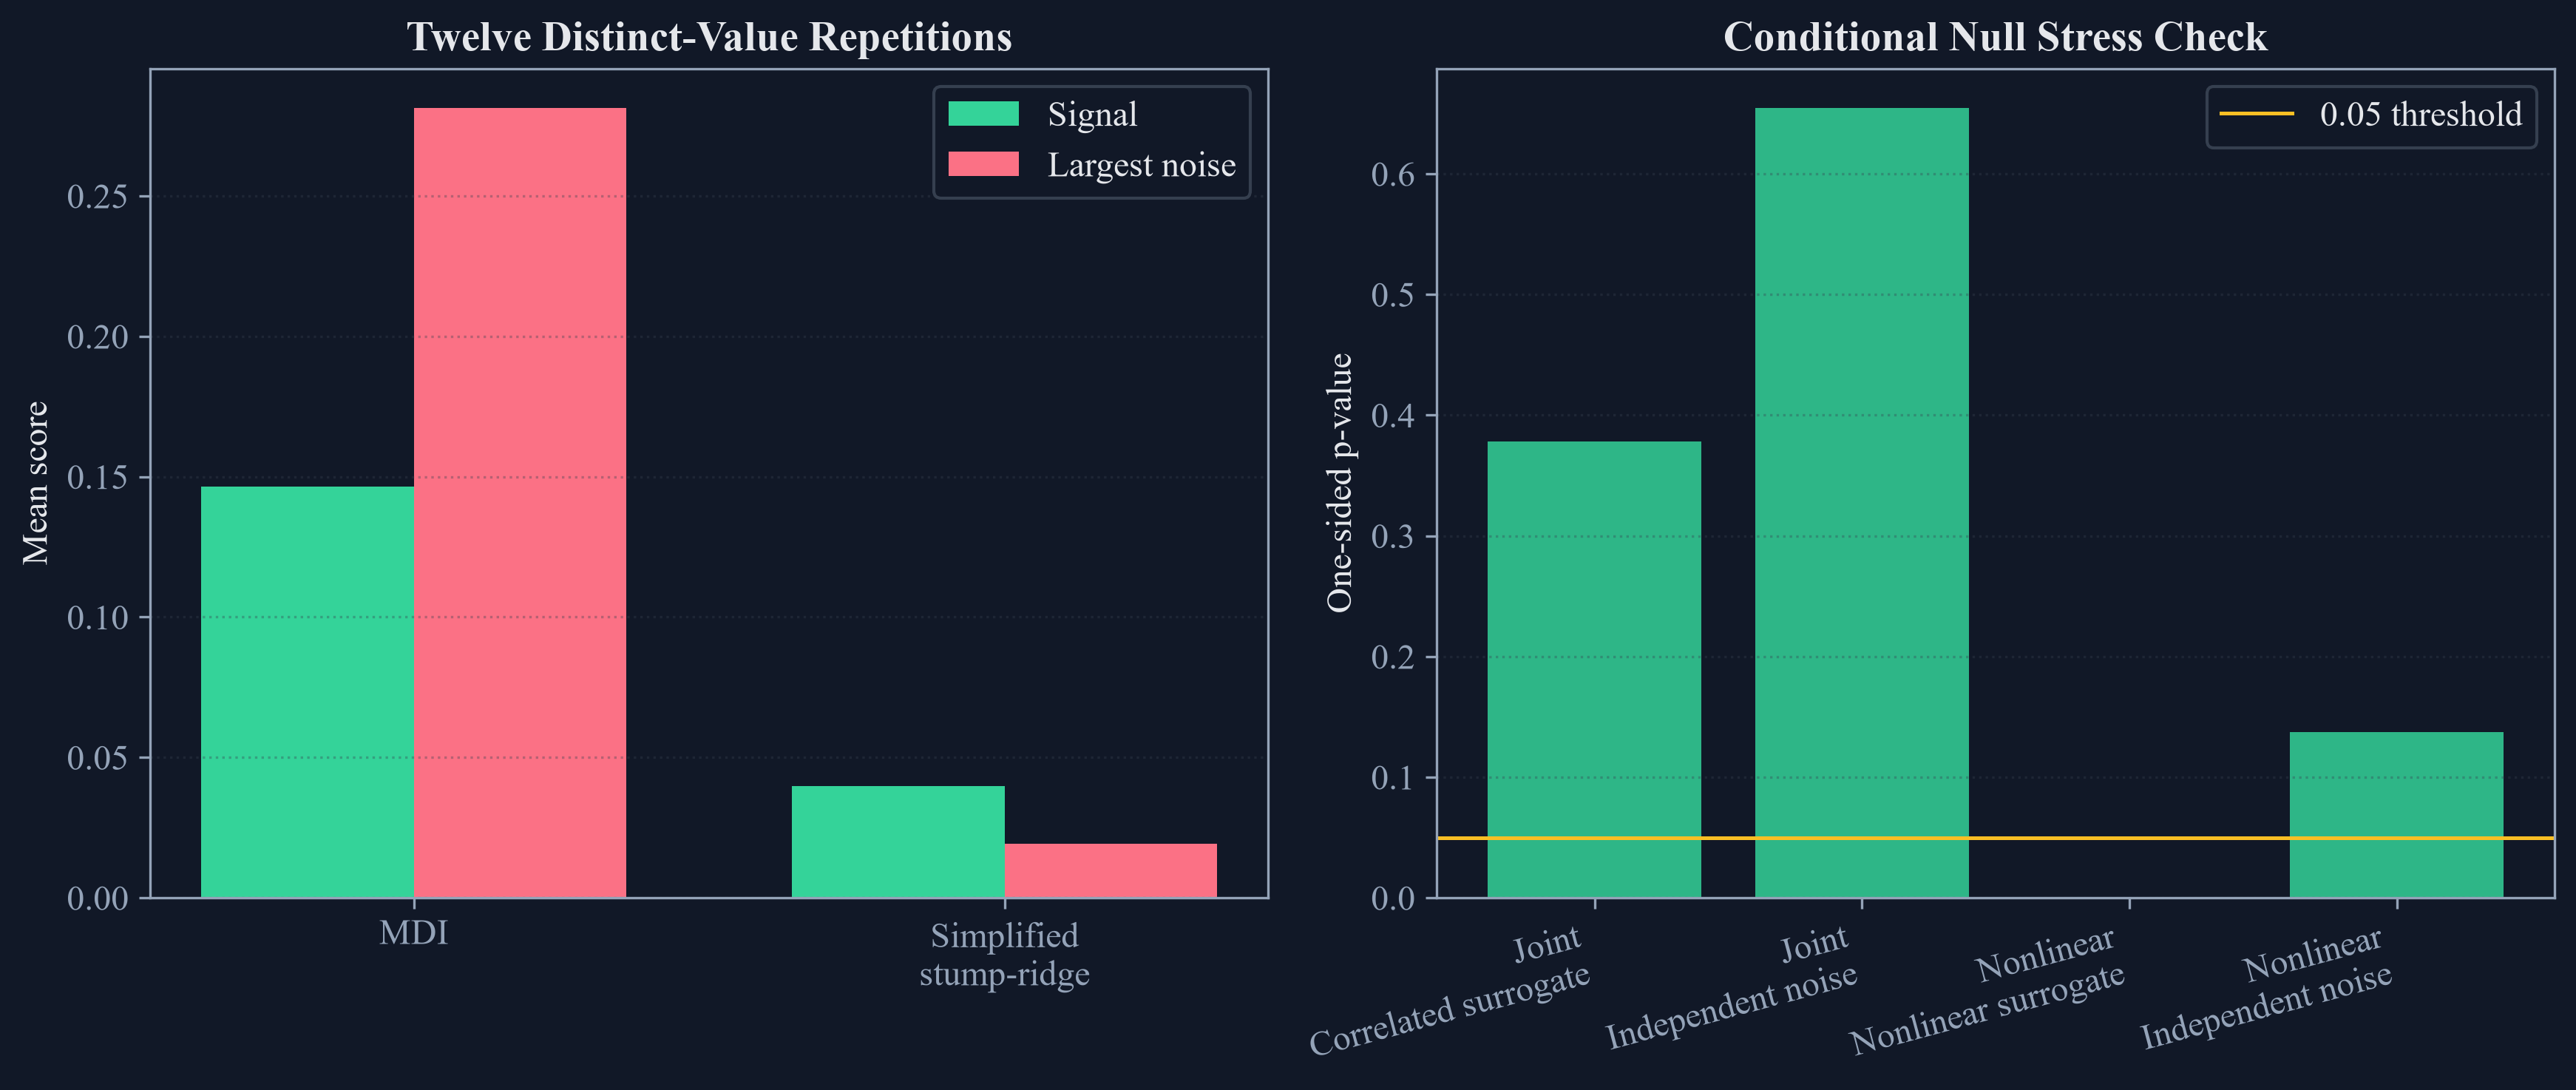

In [4]:
cpi_rows = []
for design_name, nonlinear, current_seed in [("Joint Gaussian dependence", False, 14001), ("Nonlinear dependence", True, 15001)]:
    current_rng = np.random.default_rng(current_seed)
    current_count = 1200
    direct_signal = current_rng.normal(size=current_count)
    if nonlinear:
        surrogate = direct_signal ** 2 + 0.15 * current_rng.normal(size=current_count)
        surrogate_name = "Nonlinear surrogate"
    else:
        surrogate = 0.9 * direct_signal + np.sqrt(1.0 - 0.9 ** 2) * current_rng.normal(size=current_count)
        surrogate_name = "Correlated surrogate"
    second_signal = current_rng.normal(size=current_count)
    independent_noise = current_rng.normal(size=current_count)
    current_y = pd.Series((1.4 * direct_signal + 0.9 * second_signal + 0.9 * current_rng.normal(size=current_count) > 0).astype(int))
    current_x = pd.DataFrame({"Direct signal": direct_signal, surrogate_name: surrogate, "Second signal": second_signal, "Independent noise": independent_noise})
    cpi_forest = RandomForestClassifier(n_estimators=80, max_depth=6, min_samples_leaf=8, max_features=2, random_state=current_seed, n_jobs=1, bootstrap=True)
    current_cpi = conditional_predictive_impact(current_x, current_y, random_state=current_seed, n_splits=4, n_estimators=80, classifier=cpi_forest)
    for feature, row in current_cpi.iterrows():
        role = "Conditional null" if "surrogate" in feature.lower() or feature == "Independent noise" else "Direct signal"
        cpi_rows.append({"Design": design_name, "Feature": feature, "Role": role, "CPI": row["importance"], "One-sided p-value": row["p_value"], "Below 0.05": row["p_value"] < 0.05})
cpi_controlled = pd.DataFrame(cpi_rows)
save_table(cpi_controlled, "cpi_controlled", "Conditional-impact approximation under linear-Gaussian and nonlinear dependence.", "tab:chapter12-cpi-controlled", fit=True)
display(cpi_controlled.round(6))

method_scope = pd.DataFrame({
    "Calculation": ["Published MDI+", "Released simplified stump-ridge score", "Published CPI", "Released conditional-impact approximation"],
    "Main ingredients": ["Augmented representation, chosen generalized linear model, sample splitting, chosen similarity measure", "Tree split indicators, fixed ridge fit, out-of-bag partial variance", "Valid knockoff sampler, out-of-sample paired loss", "Ridge conditional mean, Gaussian residual draw, out-of-fold paired log loss"],
    "Interpretation": ["Paper method", "Related simplified library calculation", "Paper method under valid knockoffs", "Approximation whose quality depends on the conditional model"],
})
save_table(method_scope, "method_scope", "Scope of the published methods and the released simplified calculations.", "tab:chapter12-method-scope", fit=True)
display(method_scope)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
positions = np.arange(2)
axes[0].bar(positions - 0.18, mdi_plus_controlled["Mean signal score"], 0.36, color=palette["green"], label="Signal")
axes[0].bar(positions + 0.18, mdi_plus_controlled["Mean largest-noise score"], 0.36, color=palette["rose"], label="Largest noise")
axes[0].set_xticks(positions, ["MDI", "Simplified\nstump-ridge"])
axes[0].set_title("Twelve Distinct-Value Repetitions")
axes[0].set_ylabel("Mean score")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.35)
cpi_plot = cpi_controlled[cpi_controlled["Role"] == "Conditional null"].copy()
labels = [f"{row.Design.split()[0]}\n{row.Feature}" for row in cpi_plot.itertuples(index=False)]
colors = [palette["green"] if value >= 0.05 else palette["rose"] for value in cpi_plot["One-sided p-value"]]
axes[1].bar(np.arange(len(cpi_plot)), cpi_plot["One-sided p-value"], color=colors, alpha=0.85)
axes[1].axhline(0.05, color=palette["amber"], linewidth=1.2, label="0.05 threshold")
axes[1].set_xticks(np.arange(len(cpi_plot)), labels, rotation=15, ha="right")
axes[1].set_title("Conditional Null Stress Check")
axes[1].set_ylabel("One-sided p-value")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.35)
figure.savefig(FIGURES / "corrected_conditional_stress.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "corrected_conditional_stress.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "corrected_conditional_stress.png")))
plt.close(figure)

## Tests

In [5]:
assert public_components.shape == (1755, 7)
assert public_eigen.shape == (7, 3)
assert public_eigen['EigenValue'].is_monotonic_decreasing
assert public_eigen['CumulativeVariance'].iloc[-2] < 0.9
assert public_eigen['CumulativeVariance'].iloc[-1] >= 0.9
assert np.abs(off_diagonal).max() < 1e-09
assert component_mdi.shape == (7, 2)
assert np.isclose(component_mdi['Mean'].sum(), 1.0)
assert -1.0 <= weighted_tau <= 1.0
assert weighted_tau < 0
assert component_importance.shape == (7, 6)
assert mdi_plus_paths.shape == (12, 7)
assert mdi_plus_controlled.shape == (2, 4)
assert mdi_plus_paths['MDI ranks signal first'].sum() == 0
assert mdi_plus_paths['Released simplified score ranks signal first'].sum() == 12
assert mdi_plus_controlled.iloc[1]['Mean signal score'] > mdi_plus_controlled.iloc[1]['Mean largest-noise score']
assert cpi_controlled.shape == (8, 6)
assert cpi_controlled['One-sided p-value'].between(0, 1).all()
assert cpi_controlled[(cpi_controlled['Design'] == 'Joint Gaussian dependence') & (cpi_controlled['Feature'] == 'Correlated surrogate')]['Below 0.05'].item() == False
assert cpi_controlled[(cpi_controlled['Design'] == 'Joint Gaussian dependence') & (cpi_controlled['Feature'] == 'Independent noise')]['Below 0.05'].item() == False
assert cpi_controlled[(cpi_controlled['Design'] == 'Nonlinear dependence') & (cpi_controlled['Feature'] == 'Nonlinear surrogate')]['Below 0.05'].item() == True
assert cpi_controlled[cpi_controlled['Role'] == 'Direct signal']['Below 0.05'].all()
assert method_scope.shape == (4, 3)
assert (FIGURES / 'public_orthogonal_rank.pdf').is_file()
assert (FIGURES / 'corrected_conditional_stress.pdf').is_file()
assert (TABLES / 'orthogonal_summary.tex').is_file()
assert (TABLES / 'component_importance.tex').is_file()
assert (TABLES / 'mdi_plus_controlled.tex').is_file()
assert (TABLES / 'cpi_controlled.tex').is_file()
assert (TABLES / 'method_scope.tex').is_file()
